# Observed heat and cold at Toronto Pearson

Audit NOAA ISD station **71624099999** over **2000–2024**, then fit return
levels for annual extremes of sampled air temperature. This complements a
reanalysis baseline with a station record and an explicit coverage audit.

Requires **crc-sdk 0.9.0a1 or later**, Python 3.12+, and internet access on the
first run. The first run downloads roughly 130 MB of station/year CSV data;
only small daily summaries remain in the cache. No API key is required.

ISD's `TMP` field is instantaneous sampled temperature. These indicators are
`isd_temperature_max` and `isd_temperature_min`; they are not instrument-based
daily TXx/TNn. NOAA stopped updating ISD in August 2025; use GHCNh for current
observations. Missing objects and incomplete years remain visible below.

In [1]:
#@title Install dependencies and prepare this notebook
import importlib
import importlib.metadata
import importlib.util
import os
from pathlib import Path
import subprocess
import sys
import sysconfig

if sys.version_info < (3, 12):
    raise RuntimeError("Use a Python 3.12+ runtime (Colab: Runtime > Change runtime type).")

REQUIREMENTS = [
    "crc-sdk[geometry]>=0.9.0a1,<0.10", "crc-framework>=0.4.0,<1",
    "duckdb>=1.4.5,<2", "numpy>=1.26,<3", "pandas>=2.2,<4",
    "plotly==6.9.0", "nbformat>=5.10,<6",
]
loaded_versions = {
    module: getattr(sys.modules[module], "__version__", None)
    for module in ("numpy", "pandas", "pyarrow", "plotly", "duckdb", "crc_sdk", "crc_framework")
    if module in sys.modules
}

def dependencies_ready():
    try:
        from packaging.requirements import Requirement
        for requirement in map(Requirement, REQUIREMENTS):
            version = importlib.metadata.version(requirement.name)
            if version not in requirement.specifier:
                return False
        return all(importlib.util.find_spec(name) is not None
                   for name in ("h3", "h3ronpy", "shapely"))
    except (ImportError, importlib.metadata.PackageNotFoundError):
        return False

if not dependencies_ready():
    if importlib.util.find_spec("pip") is None:
        subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"])
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check",
        *REQUIREMENTS,
    ])
importlib.invalidate_caches()
for module, loaded in loaded_versions.items():
    installed = importlib.metadata.version(module.replace("_", "-"))
    if loaded is not None and loaded != installed:
        raise RuntimeError("Packages changed after import. Restart the kernel, then run all cells again.")
os.environ["PATH"] = sysconfig.get_path("scripts") + os.pathsep + os.environ.get("PATH", "")
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
print(f"crc-sdk {importlib.metadata.version('crc-sdk')} ready. Run the remaining cells in order.")


crc-sdk 0.9.0a1 ready. Run the remaining cells in order.


In [2]:
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display

from crc_sdk.workflows import (
    HazardDataset, BlockExtremaPolicy, curve_quantiles,
    return_periods_to_probabilities,
)
from crc_sdk.connectors.blocks import plotting_position_curve
import numpy as np

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470
pd.options.display.max_rows = 80


## Plan the baseline

A day needs valid observations in at least **18 distinct UTC hour bins**.
A year needs at least **90% of its calendar days** to pass, including leap
days and absent days in the denominator. Only TMP quality codes **1 and 5**
(all checks passed) are accepted. Duplicate and subhourly reports cannot
inflate the hourly coverage count. The daily extremes use every accepted
sample in a passing day.

The plan is immutable and lazy. Four workers each have a 256 MB DuckDB memory
limit; Arrow reads 1 MiB CSV blocks. DuckDB may spill aggregations to scratch
storage. The cache holds daily min/max and QC counts shared by both tails.

`.for_area(bounds)` resolves catalogue station locations within the same WGS84
bounding-box syntax used by gridded adapters. `.stations()` reads station
metadata only, and `.resolve_stations()` pins explicit IDs in a new plan.
The catalogue is cached across areas and recipes and is available offline.
`.for_areas([box1, box2])` selects a union without duplicate stations. Selection
uses catalogue locations; fitted curves retain point support. This notebook
shows one station; the pipeline supports multiple selected stations.

In [3]:
BOUNDS = (-79.64, 43.67, -79.62, 43.69)
START, END = 2000, 2024
OUTPUT = Path("pipeline_output/noaa_isd")
OUTPUT.mkdir(parents=True, exist_ok=True)
base = (
    HazardDataset.isd().for_area(BOUNDS).years(START, END)
    .quality(minimum_hour_fraction=0.75, minimum_day_fraction=0.9)
    .execution(workers=4, memory_limit="256MB")
    .cache(OUTPUT / "cache", mode="reuse")
)
print(base.explain())
selected = base.stations()
display(selected.to_pandas())
if selected.num_rows != 1:
    raise ValueError("Narrow BOUNDS to one station for this notebook; use the pipeline for multiple stations.")
base = base.resolve_stations()
STATIONS = list(base.selected_stations)
print(base.prefetch())

{
  "version": "isd-2025-08-24",
  "provider": "isd",
  "stations": [],
  "areas": [
    [
      -79.64,
      43.67,
      -79.62,
      43.69
    ]
  ],
  "years": [
    2000,
    2001,
    2002,
    2003,
    2004,
    2005,
    2006,
    2007,
    2008,
    2009,
    2010,
    2011,
    2012,
    2013,
    2014,
    2015,
    2016,
    2017,
    2018,
    2019,
    2020,
    2021,
    2022,
    2023,
    2024
  ],
  "completeness": {
    "minimum_hour_fraction": 0.75,
    "minimum_day_fraction": 0.9,
    "quality_codes": [
      "1",
      "5"
    ]
  },
  "recipe": "temperature_max",
  "daily_boundary": "UTC",
  "reduction_version": 1,
  "hazard_name": "isd_temperature_max",
  "unit": "degC",
  "spatial_support": "station point; H3 index only; no area interpolation",
  "cache": {
    "mode": "reuse",
    "directory": "pipeline_output/noaa_isd/cache",
    "object": "station/year daily min/max and quality counts"
  },
  "execution": {
    "workers": 4,
    "memory_limit_per_worker":

,station,name,latitude,longitude,elevation,start_year,end_year
0,71624099999,LESTER B PEARSON INTL,43.677,-79.631,173.4,1950,2025


PrefetchResult(source_version='isd-2025-08-24', cache_hits=25, cache_misses=0, resources=25)


## Inspect the years before fitting

HTTP 404 means an absent station/year object and is recorded as an excluded
year with a null extreme. Other network errors stop execution. For this AWS
record, 2005 is absent. Review station coordinates, elevation and QC counts
before interpreting the extremes; instrumentation and reporting practices can
change even when a station ID stays the same.

,station,year,latitude,longitude,elevation,valid_days,expected_days,accepted_reports,reports,value,complete
0,71624099999,2000,43.677223,-79.630556,173.43,364,366,8666,10816,31.0,True
1,71624099999,2001,43.677223,-79.630556,173.43,365,365,8684,10563,37.0,True
2,71624099999,2002,43.677223,-79.630556,173.43,361,365,8600,10657,35.1,True
3,71624099999,2003,43.677223,-79.630556,173.43,362,365,8556,10822,34.0,True
4,71624099999,2004,43.677223,-79.630556,173.43,362,366,8636,10655,31.8,True
5,71624099999,2005,NaN,NaN,NaN,0,365,0,0,NaN,False
6,71624099999,2006,43.677223,-79.630556,173.43,362,365,10322,10357,36.0,True
7,71624099999,2007,43.677223,-79.630556,173.43,364,365,10260,10314,35.0,True
8,71624099999,2008,43.677223,-79.630556,173.43,366,366,10613,10624,33.0,True
9,71624099999,2009,43.677223,-79.630556,173.43,365,365,10260,10264,31.0,True


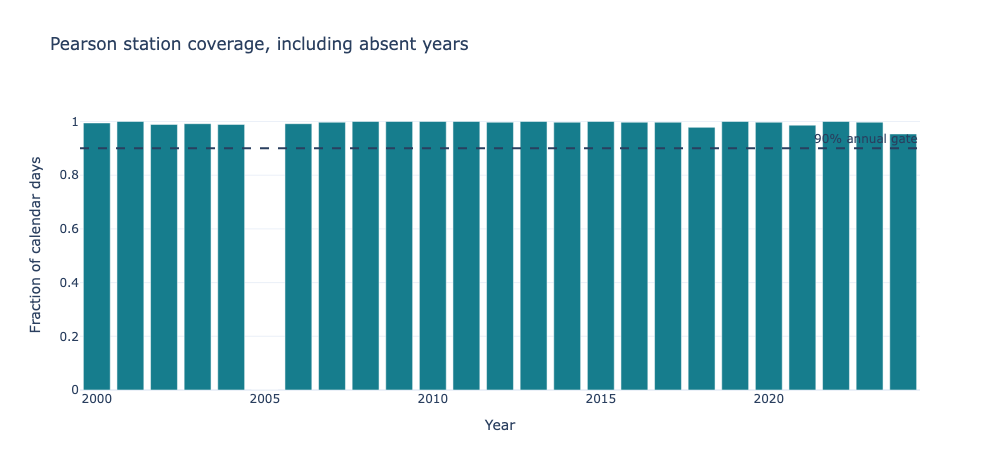

In [4]:
annual = base.annual_extremes().to_pandas()
display(annual)
coverage = go.Figure(go.Bar(
    x=annual["year"], y=annual["valid_days"] / annual["expected_days"],
    marker_color=np.where(annual["complete"], "#167d8d", "#c44e52"),
    name="Valid day fraction",
))
coverage.add_hline(y=0.9, line_dash="dash", annotation_text="90% annual gate")
coverage.update_layout(title="Pearson station coverage, including absent years",
                       xaxis_title="Year", yaxis_title="Fraction of calendar days",
                       yaxis_range=[0, 1.08])
coverage.show()

## Fit separate heat and cold curves

At least **20 complete years** are required per station. The heat recipe uses
GEV sample L-moments; the cold recipe uses lower-tail Gumbel L-moments. Both
reuse the SDK's block-extrema fitting and validation policy. Diagnostics trace
fits and skipped stations. H3 is a lookup index; the stored geometry is the
station **point**, with no regional interpolation or nearby-asset coverage.

Changing the fitting policy reuses daily reductions. Explicit offline mode
checks local file hashes and performs no network requests.

temperature_max complete years: 24 fitted stations: 1


,cell_index,source_id,hazard_name,horizon,pathway,outcome,curve_type,normalized_rmse,maximum_absolute_residual,negative_log_likelihood,...,residual_scale_floor,censored_point_count,uncensored_point_count,attempted_families,failed_families,fallback,reason,message,treatment,minimum_informative_value
0,599745921793654783,noaa-isd:71624099999,isd_temperature_max,2012,historical,fitted,genextreme,NaN,NaN,NaN,...,NaN,NaN,NaN,[genextreme],[],False,NaN,24 blocks,sample_lmoments,NaN


temperature_min complete years: 24 fitted stations: 1


,cell_index,source_id,hazard_name,horizon,pathway,outcome,curve_type,normalized_rmse,maximum_absolute_residual,negative_log_likelihood,...,residual_scale_floor,censored_point_count,uncensored_point_count,attempted_families,failed_families,fallback,reason,message,treatment,minimum_informative_value
0,599745921793654783,noaa-isd:71624099999,isd_temperature_min,2012,historical,fitted,gumbel_l,NaN,NaN,NaN,...,NaN,NaN,NaN,[gumbel_l],[],False,NaN,24 blocks,sample_lmoments,NaN


Resorting to unclean kill browser.


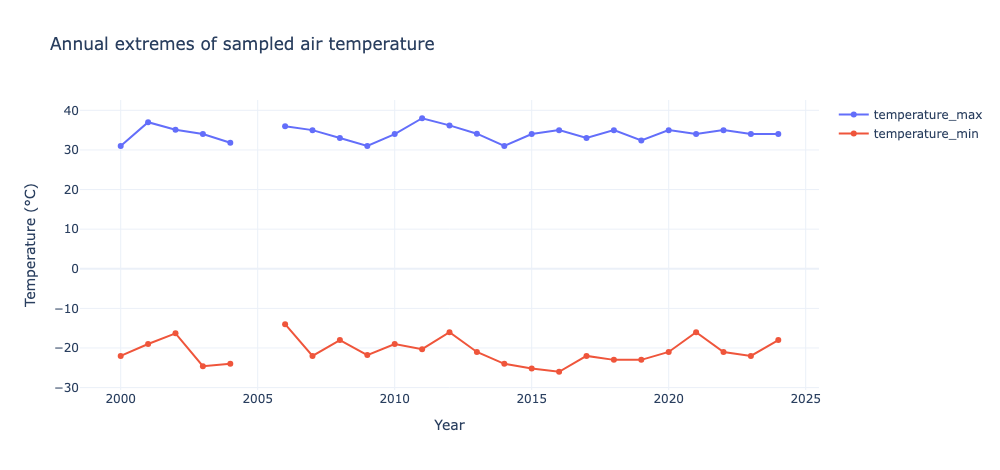

In [5]:
results = {}
for recipe, tail in (("temperature_max", "upper"), ("temperature_min", "lower")):
    plan = (
        HazardDataset.isd(recipe).for_area(BOUNDS).years(START, END)
        .cache(OUTPUT / "cache", mode="offline")
        .canonicalize(policy=BlockExtremaPolicy.curated(
            minimum_years=20,
            diagnostics=OUTPUT / f"{recipe}_diagnostics.parquet",
        ))
    )
    plan.write_annual_extremes(OUTPUT / f"{recipe}_annual.parquet")
    path = OUTPUT / f"{recipe}_curves.parquet"
    plan.materialize(path)
    curves = pq.ParquetFile(path).read()
    series = plan.annual_extremes().to_pandas()
    results[recipe] = (tail, curves, series)
    print(recipe, "complete years:", int(series["complete"].sum()),
          "fitted stations:", curves.num_rows)
    display(pq.ParquetFile(OUTPUT / f"{recipe}_diagnostics.parquet").read().to_pandas())

observations = go.Figure()
for recipe, (tail, curves, series) in results.items():
    observations.add_trace(go.Scatter(
        x=series["year"], y=series["value"], mode="lines+markers", name=recipe,
        connectgaps=False,
    ))
observations.update_layout(title="Annual extremes of sampled air temperature",
                           xaxis_title="Year", yaxis_title="Temperature (°C)")
observations.show()

## Compare empirical extremes and fitted return levels

The Gringorten points show the complete-year samples entering each fit.
A fitted 1-in-20-year value is an annual exceedance (heat) or non-exceedance
(cold) quantile under a **stationary baseline** assumption. It is not a forecast
of the year in which an event will happen. A 25-year window provides limited
tail information; 50- and 100-year levels extrapolate well beyond the record
and have substantial uncertainty. No confidence intervals are estimated here.

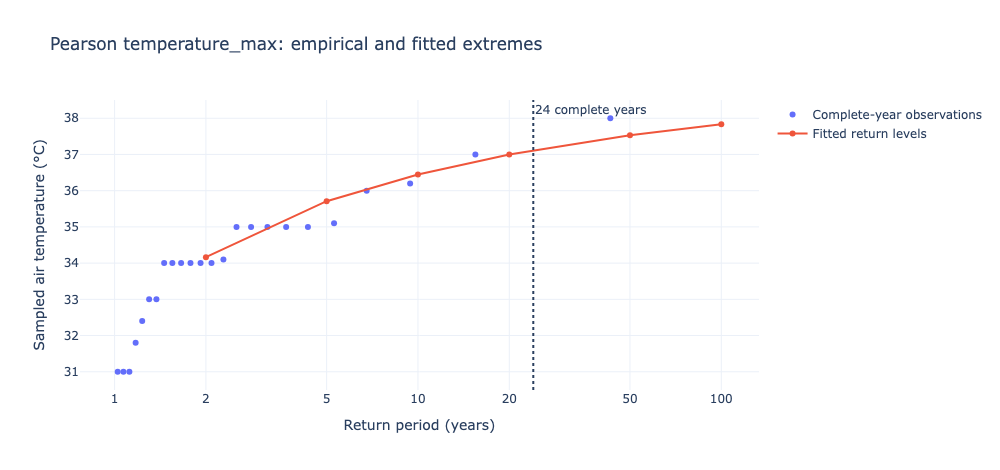

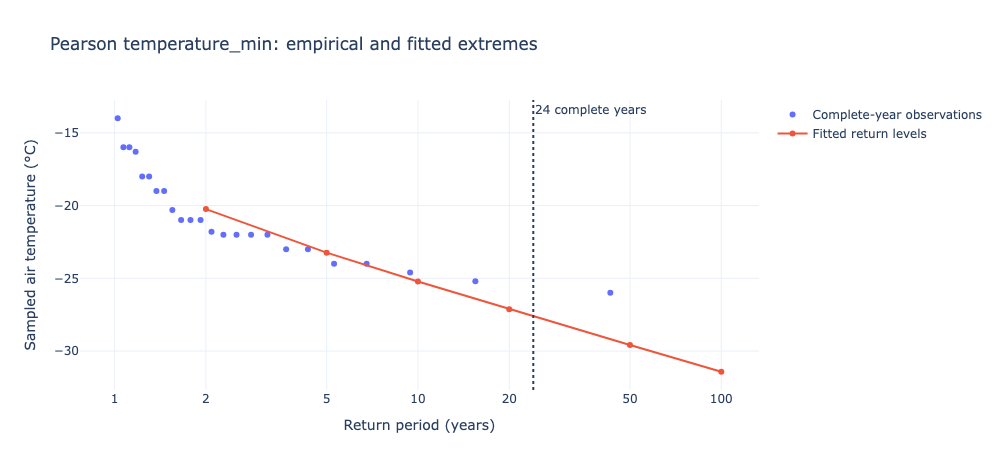

,recipe,return_period_years,temperature_degC
0,temperature_max,2.0,34.163421
1,temperature_max,5.0,35.709099
2,temperature_max,10.0,36.446941
3,temperature_max,20.0,36.996619
4,temperature_max,50.0,37.533303
5,temperature_max,100.0,37.836695
6,temperature_min,2.0,-20.243695
7,temperature_min,5.0,-23.236210
8,temperature_min,10.0,-25.217516
9,temperature_min,20.0,-27.118032


In [6]:
periods = (2., 5., 10., 20., 50., 100.)
level_rows = []
for recipe, (tail, curves, series) in results.items():
    if curves.num_rows == 0:
        raise RuntimeError(f"No fitted curve for {recipe}; review coverage and diagnostics")
    probabilities = return_periods_to_probabilities(periods, tail=tail)
    levels = curve_quantiles(curves, probabilities, max_workers=1)[0]
    empirical_rp, empirical_values = plotting_position_curve(
        series["value"].to_numpy(dtype=float), tail,
    )
    chart = go.Figure()
    chart.add_trace(go.Scatter(x=empirical_rp, y=empirical_values,
                              mode="markers", name="Complete-year observations"))
    chart.add_trace(go.Scatter(x=periods, y=levels,
                              mode="lines+markers", name="Fitted return levels"))
    complete_years = int(series["complete"].sum())
    chart.add_vline(x=complete_years, line_dash="dot")
    chart.add_annotation(x=np.log10(complete_years), y=1, xref="x", yref="paper",
                         text=f"{complete_years} complete years", showarrow=False,
                         xanchor="left")
    chart.update_layout(title=f"Pearson {recipe}: empirical and fitted extremes",
                        xaxis_title="Return period (years)", xaxis_type="log",
                        xaxis_tickvals=[1, 2, 5, 10, 20, 50, 100],
                        yaxis_title="Sampled air temperature (°C)")
    chart.show()
    level_rows.extend({"recipe": recipe, "return_period_years": period,
                       "temperature_degC": value}
                      for period, value in zip(periods, levels))
display(pd.DataFrame(level_rows))

## Reuse and interpret the artifacts

The output directory contains daily cache summaries with checksums and request
provenance, annual audit series, canonical station curves, and fit diagnostics.
The matching pipeline, `pipelines/noaa_isd_pipeline.py`, writes both tails and
a return-level table and accepts station IDs, years, worker count and cache
mode as command-line arguments.

These are derived NOAA observations. Sparse sampling, changing instruments,
station moves and seasonal gaps can affect extremes. The coordinate check
rejects jumps larger than 0.05 degrees; smaller changes still need scientific
review. The SDK does not homogenize the observations. Comparing these values
with ERA5/CMIP6 requires matching the variable definition, temporal window,
daily boundary and station/grid representativeness. This notebook makes no
claim of gridded-model validation.

Sources: [AWS ISD archive and NODD terms](https://registry.opendata.aws/noaa-isd/),
[NOAA retirement notice](https://www.nesdis.noaa.gov/news/service-location-change-integrated-surface-data-global-hourly),
[ISD format and QC codes](https://www.ncei.noaa.gov/pub/data/noaa/isd-format-document.pdf),
[GHCNh successor](https://www.ncei.noaa.gov/products/global-historical-climatology-network-hourly).
Modified data, derived from NOAA ISD; no NOAA endorsement implied. National
originator terms can apply to contributions; do not assume a blanket CC0 licence.

## Use the GHCNh successor with the same workflow

NOAA's **Global Historical Climatology Network hourly (GHCNh)** replaces ISD
and continues daily updates. Its adapter shares the completeness gates,
daily-summary schema, annual audit and fitter. It reads eight Parquet columns
with conditional HTTP range requests and bounded Arrow batches. Temperature
values are already Celsius. QC is source-aware: legacy code `5` is accepted
only for sources where it means passed, and excluded where it means removed.

This example inspects **2025 at Chicago O'Hare (`USW00094846`)**. The area is resolved through the GHCNh catalogue. Explicit
`.for_stations(...)` calls use GHCN identifiers; matching an ISD station requires
station-history verification. GHCNh has distinct cache identities, source IDs and indicator
names, so both sources can share a cache directory safely. Its AWS registry
labels the product CC0-1.0; derived outputs retain attribution.

A single year is useful for an observation audit. Fitting still requires at
least 20 complete years by default. Run the paired pipeline for a full GHCNh
baseline:

```shell
python pipelines/noaa_isd_pipeline.py --source ghcnh --bounds -87.94 41.95 -87.92 41.97
```

[NOAA GHCNh overview](https://www.ncei.noaa.gov/products/global-historical-climatology-network-hourly)
· [GHCNh archive and terms](https://registry.opendata.aws/noaa-ghcnh/)
· [Station identifiers](https://noaa-ghcnh-pds.s3.amazonaws.com/hourly/doc/ghcnh-station-list.csv)

In [7]:
ghcnh_plan = (
    HazardDataset.ghcnh("temperature_max")
    .for_area((-87.94, 41.95, -87.92, 41.97))
    .years(2025, 2025)
    .quality(minimum_hour_fraction=0.75, minimum_day_fraction=0.9)
    .cache(OUTPUT.parent / "noaa_ghcnh" / "cache", mode="reuse")
)
display(ghcnh_plan.stations().to_pandas())
print(ghcnh_plan.prefetch())
display(ghcnh_plan.annual_extremes().to_pandas())

,station,name,latitude,longitude,elevation,start_year,end_year
0,USW00094846,CHICAGO OHARE INTL AP,41.9603,-87.9317,204.8,NaN,NaN


PrefetchResult(source_version='ghcnh-v1', cache_hits=1, cache_misses=0, resources=1)


,station,year,latitude,longitude,elevation,valid_days,expected_days,accepted_reports,reports,value,complete
0,USW00094846,2025,41.9603,-87.9317,204.8,361,365,13419,13440,34.4,True
